In [3]:
%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np 
import pandas as pd 
from sklearn.model_selection import train_test_split, KFold, cross_val_score 
from sklearn.dummy import DummyRegressor 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler, PolynomialFeatures 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
df = pd.read_csv("lab_ticket_resolution.csv") 
print(df.shape) 
print(df.dtypes) 
print(df.describe(include="all")) 
print(df.isna().sum()) 

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [5]:
y = df["resolution_hours"]

features = [
    "complexity_score",
    "team_experience_years"
]

X = df[features]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

Target:
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64


In [7]:
X = df[["complexity_score", "team_experience_years"]]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training target: (192,)
Testing target: (48,)


In [9]:
df = pd.read_csv("lab_ticket_resolution.csv")

print("Dataset shape:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
print(df.describe(include="all"))

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five rows:")
print(df.head())

Dataset shape:
(240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54

In [10]:
y = df["resolution_hours"]

features = ["complexity_score", "team_experience_years"]
X = df[features]

print("Selected features:", features)
print("Target: resolution_hours")

Selected features: ['complexity_score', 'team_experience_years']
Target: resolution_hours


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (192, 2)
X_test: (48, 2)
y_train: (192,)
y_test: (48,)


In [13]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print(f"\n{name}")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R2: {r2:.3f}")

    return predictions, mae, rmse, r2


results = {}

In [14]:
dummy = DummyRegressor(strategy="mean")

results["Dummy"] = evaluate_model(
    "Dummy Regressor", dummy
)


Dummy Regressor
MAE: 9.114
RMSE: 10.598
R2: -0.021


In [15]:
linear = LinearRegression()

results["Linear"] = evaluate_model(
    "Linear Regression", linear
)

print("\nIntercept:", linear.intercept_)
print("Coefficients:")

for feature, coefficient in zip(features, linear.coef_):
    print(feature, ":", coefficient)


Linear Regression
MAE: 2.906
RMSE: 3.572
R2: 0.884

Intercept: 4.249331563721064
Coefficients:
complexity_score : 3.0799389415109713
team_experience_years : -0.31806778796168594


In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for degree in [2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    print(f"\nPolynomial degree {degree}")
    print(f"Mean CV RMSE: {-scores.mean():.3f}")
    print(f"CV RMSE standard deviation: {scores.std():.3f}")

    results[f"Polynomial {degree}"] = evaluate_model(
        f"Polynomial Regression Degree {degree}", model
    )


Polynomial degree 2
Mean CV RMSE: 3.832
CV RMSE standard deviation: 0.461

Polynomial Regression Degree 2
MAE: 3.020
RMSE: 3.741
R2: 0.873

Polynomial degree 3
Mean CV RMSE: 3.877
CV RMSE standard deviation: 0.314

Polynomial Regression Degree 3
MAE: 3.140
RMSE: 3.949
R2: 0.858


In [19]:
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

ridge_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best CV RMSE:", -ridge_search.best_score_)

results["Ridge"] = evaluate_model(
    "Ridge Regression", ridge_search.best_estimator_
)

Best Ridge alpha: 0.1
Best CV RMSE: 3.9092037889673357

Ridge Regression
MAE: 2.906
RMSE: 3.572
R2: 0.884


In [18]:
from sklearn.model_selection import GridSearchCV

In [20]:
lasso_search = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        Lasso(max_iter=10000)
    ),
    {"lasso__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

lasso_search.fit(X_train, y_train)

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print("Best CV RMSE:", -lasso_search.best_score_)

results["Lasso"] = evaluate_model(
    "Lasso Regression", lasso_search.best_estimator_
)

Best Lasso alpha: 0.001
Best CV RMSE: 3.909251978309689

Lasso Regression
MAE: 2.906
RMSE: 3.572
R2: 0.884


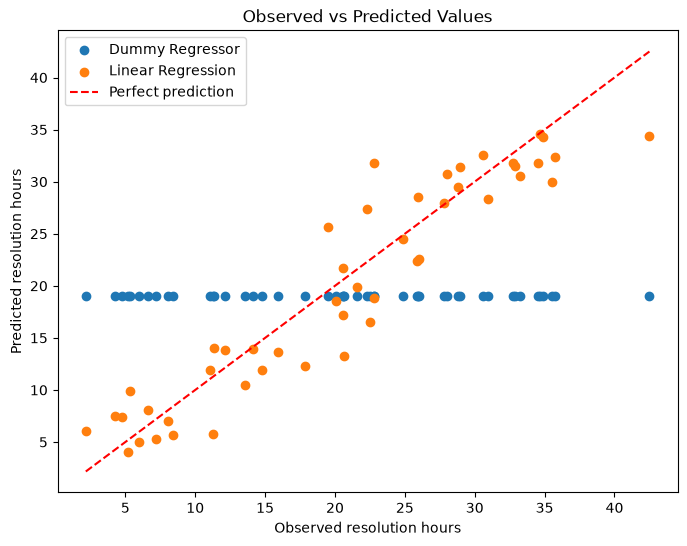

In [21]:
dummy_predictions = dummy.predict(X_test)
linear_predictions = linear.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, dummy_predictions, label="Dummy Regressor")
plt.scatter(y_test, linear_predictions, label="Linear Regression")

low = min(y_test.min(), dummy_predictions.min(), linear_predictions.min())
high = max(y_test.max(), dummy_predictions.max(), linear_predictions.max())

plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Observed resolution hours")
plt.ylabel("Predicted resolution hours")
plt.title("Observed vs Predicted Values")
plt.legend()
plt.show()

In [22]:
summary = pd.DataFrame({
    name: {
        "MAE": metrics[1],
        "RMSE": metrics[2],
        "R2": metrics[3]
    }
    for name, metrics in results.items()
}).T

print(summary.sort_values("RMSE").round(3))

                MAE    RMSE     R2
Ridge         2.906   3.572  0.884
Linear        2.906   3.572  0.884
Lasso         2.906   3.572  0.884
Polynomial 2  3.020   3.741  0.873
Polynomial 3  3.140   3.949  0.858
Dummy         9.114  10.598 -0.021


Question 9: Write a short recommendation: which model would you choose for this dataset, what evidence supports it, and what further data or checks would be needed? 

I would choose Linear Regression for this dataset because it gave good results without adding unnecessary complexity. It achieved an MAE of 2.906, an RMSE of 3.572, and an R² of 0.884. Ridge and Lasso achieved the same scores, while the polynomial models performed slightly worse. Before making a final decision, I would test the model on new data, check for data leakage, and use cross-validation to see if the results stay consistent. I would also check whether the dataset contains enough examples from different ticket types and time periods. These checks would help me decide whether Linear Regression is reliable enough for real use


Question 10 - 17


Question 10 : Why is the mean baseline useful even though it ignores all features?

Even though the mean baseline does not use any features, it helps us understand how well our other models are doing. It always predicts the average target value, so we can use it as a starting point. If a model cannot do better than this simple method, then it may not be learning useful information from the data

Question 11: Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ? 

In my results Linear Regression, Ridge, and Lasso performed equally well. All three had an MAE of 2.906 and an RMSE of 3.572. This means they had the lowest scores for both measurements.The two metrics measure errors in different ways. MAE looks at the average size of the errors, while RMSE penalizes larger mistakes more heavily. Because of this, one model could have a lower MAE while another has a lower RMSE. However, that did not happen in my results

Question 12: Did polynomial features improve validation performance? What is the evidence of possible overfitting?  

Adding polynomial features did not give me better results. Linear Regression performed better,with an MAE of 2.906,compared with 3.020 for degree 2 and 3.140 for degree 3. The polynomial models also had higher RMSE values and lower R² scores. This suggests that adding more complex features did not help the model predict the validation data.The degree 3 model performed worse than degree 2, which may mean that increasing the complexity was not useful.However, I would need to compare the training and validation scores to know whether the models were actually overfitting.

Question 13: How did regularization affect performance and coefficient magnitudes? 

From my results,regularization did not noticeably change prediction accuracy because Ridge, Lasso, and Linear Regression had identical scores after rounding. However,Ridge and Lasso handle the model coefficients differently from ordinary Linear Regression.Ridge tries to keep coefficients small, while Lasso can remove less useful features by reducing some coefficients to zero.These methods can make a model simpler and help prevent overfitting

Question 14: Why is scaling included in the Ridge/Lasso pipeline?

I included scaling because the features may use different measurement ranges. For example one feature might have values in the hundreds while another has values below ten. Since Ridge and Lasso penalize coefficient sizes, differences in feature scales can affect the regularization process. Scaling makes the features more comparable, and the pipeline helps apply the preprocessing steps consistently.

Question 15: Identify one potential leakage issue in the dataset and explain how you handled it. 

A possible leakage problem is using the entire dataset to calculate values needed for preprocessing before splitting it into training and validation sets. For example, calculating the mean or standard deviation from all the data allows the validation set to influence the training process.The safer approach is to split the dataset first, calculate the required values from the training set, and then use those values to transform the validation set. A pipeline can help manage these steps correctly.

Question 16: Would a random split be appropriate if tickets were collected over several years or came from repeated 
customers/teams? Explain. 

If the tickets were collected over several years, I would train the model using older records and evaluate it on newer records. This would show whether the model can make predictions about future tickets.If the dataset contained several tickets from the same customers or teams, I would consider splitting by customer or team instead. Otherwise, similar records could appear in both the training and validation sets, making the model's performance look better than it really is. Keeping groups separate would give a more realistic evaluation

Question 17: What additional tests would you perform before deploying this model? 

Testing it on a separate dataset that was not used during model selection and use cross-validation to check whether its performance stays consistent.I would also examine the prediction errors to see whether the model regularly makes large mistakes or misses certain patterns. Another important step would be checking how it performs on different ticket types and on data collected at different times. I would test how it handles missing or unusual values and make sure there are no data leakage problems.And I would compare its results with the mean baseline again. This would help me decide whether the model provides enough improvement to be useful in practice